# 03 · Análise Exploratória (EDA) com foco em negócio

Esta análise foi escrita pensando em **um(a) gerente de operações que não precisa entender estatística**. Por isso, em vez de coeficientes, falamos em:

- **Nota média** — a média das notas de 0 a 10;
- **% de detratores** — de cada 100 clientes, quantos deram nota abaixo de 7;
- **NPS** — % de promotores menos % de detratores (de −100 a +100).

As perguntas que guiam o notebook:

1. Quais fatores parecem mais críticos para a satisfação?
2. O que mais gera detratores?
3. Existe algum "ponto de ruptura" na experiência?
4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

Todos os gráficos são salvos em `reports/figures/` e reaproveitados na apresentação.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src.nps_utils import (
    FRIENDLY_NAMES, PRE_SURVEY_FEATURES, POST_EXPERIENCE_FEATURES,
    load_processed_data, nps_index, nps_summary_by,
)
from src.viz import (
    COLOR_ALERT, COLOR_MUTED, COLOR_NEUTRAL, COLOR_PRIMARY, COLOR_TEXT_SECONDARY,
    DIVERGING_CMAP, NPS_CATEGORY_COLORS, label_bars, save_figure, set_style,
)

set_style()
df = load_processed_data()
print(f"{len(df)} pedidos carregados")

2500 pedidos carregados


## 1. O ponto de partida: como está a satisfação hoje?

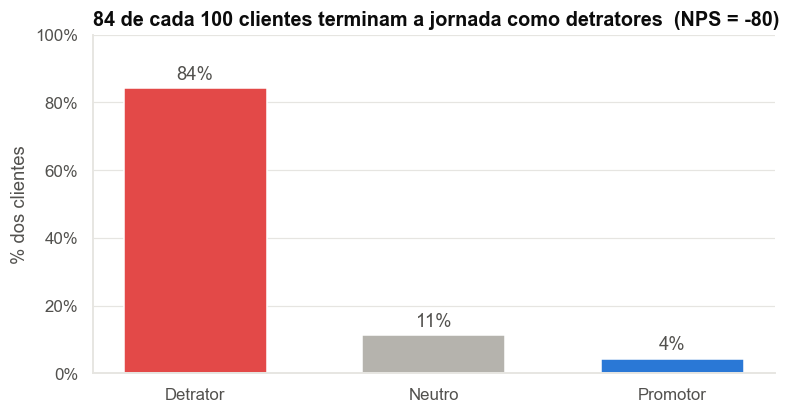

In [2]:
category_share = df["nps_category"].value_counts(normalize=True).sort_index().mul(100)
overall_nps = nps_index(df["nps_score"])

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(category_share.index, category_share.values,
              color=[NPS_CATEGORY_COLORS[c] for c in category_share.index], width=0.6)
label_bars(ax, fmt="{:.0f}", suffix="%", fontsize=12)
ax.set_title(f"84 de cada 100 clientes terminam a jornada como detratores  (NPS = {overall_nps:.0f})")
ax.set_ylabel("% dos clientes")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
save_figure(fig, "01_distribuicao_nps.png")
plt.show()

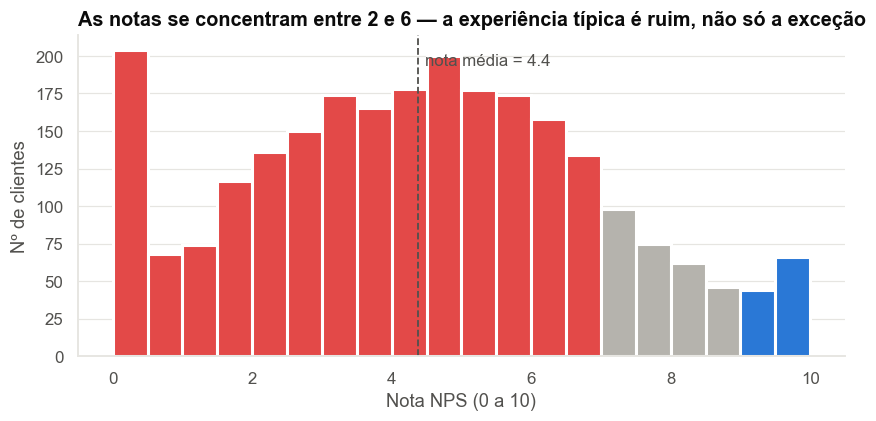

In [3]:
# Distribuição das notas: onde os clientes se concentram
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.arange(0, 10.5, 0.5)
counts, edges, patches = ax.hist(df["nps_score"], bins=bins, color=COLOR_PRIMARY, edgecolor="white", linewidth=2)
for patch, left_edge in zip(patches, edges[:-1]):
    patch.set_facecolor(COLOR_ALERT if left_edge < 7 else (COLOR_NEUTRAL if left_edge < 9 else COLOR_PRIMARY))
ax.axvline(df["nps_score"].mean(), color=COLOR_TEXT_SECONDARY, linestyle="--", linewidth=1.2)
ax.text(df["nps_score"].mean() + 0.1, counts.max() * 0.95, f"nota média = {df['nps_score'].mean():.1f}", color=COLOR_TEXT_SECONDARY)
ax.set_title("As notas se concentram entre 2 e 6 — a experiência típica é ruim, não só a exceção")
ax.set_xlabel("Nota NPS (0 a 10)")
ax.set_ylabel("Nº de clientes")
save_figure(fig, "02_histograma_notas.png")
plt.show()

**O que isso significa para a operação:** o NPS de **−80** não é causado por um pequeno grupo de clientes irritados — a nota típica está em torno de 4. O problema é **estrutural**: está no "jeito padrão" como os pedidos estão sendo entregues e atendidos. A boa notícia é que, se a causa é estrutural, ela tende a estar concentrada em poucos processos.

## 2. Quais fatores parecem mais críticos?

Primeiro, uma visão geral: quanto cada variável "anda junto" com a nota. Usamos a correlação de Spearman (de −1 a +1), que capta relações mesmo quando não são lineares. Para o negócio, leia assim: **quanto maior a barra, mais aquele fator acompanha a variação da nota**. Barras vermelhas: quanto mais, pior a nota.

In [4]:
numeric_pre_survey = [c for c in PRE_SURVEY_FEATURES if c != "customer_region"]

correlations = []
for column in numeric_pre_survey + POST_EXPERIENCE_FEATURES:
    rho, p_value = stats.spearmanr(df[column], df["nps_score"])
    correlations.append({
        "variavel": column,
        "fator": FRIENDLY_NAMES[column],
        "correlacao": rho,
        "p_valor": p_value,
        "grupo": "Pós-experiência" if column in POST_EXPERIENCE_FEATURES else "Operacional (antes da pesquisa)",
    })
correlation_table = pd.DataFrame(correlations).sort_values("correlacao", key=abs, ascending=False)
correlation_table["relevante (p<0,05)"] = correlation_table["p_valor"] < 0.05
correlation_table.round(3)

,variavel,fator,correlacao,p_valor,grupo,"relevante (p<0,05)"
7,delivery_delay_days,Atraso na entrega (dias),-0.586,0.000,Operacional (antes da pesquisa),True
14,csat_internal_score,CSAT interno,0.561,0.000,Pós-experiência,True
12,complaints_count,Nº de reclamações,-0.490,0.000,Operacional (antes da pesquisa),True
13,repeat_purchase_30d,Recompra em 30 dias,0.489,0.000,Pós-experiência,True
10,customer_service_contacts,Contatos com o SAC,-0.336,0.000,Operacional (antes da pesquisa),True
11,resolution_time_days,Tempo de resolução (dias),-0.190,0.000,Operacional (antes da pesquisa),True
8,freight_value,Frete (R$),-0.040,0.048,Operacional (antes da pesquisa),True
2,order_value,Valor do pedido (R$),0.036,0.073,Operacional (antes da pesquisa),False
5,payment_installments,Nº de parcelas,0.027,0.183,Operacional (antes da pesquisa),False
9,delivery_attempts,Tentativas de entrega,0.026,0.189,Operacional (antes da pesquisa),False


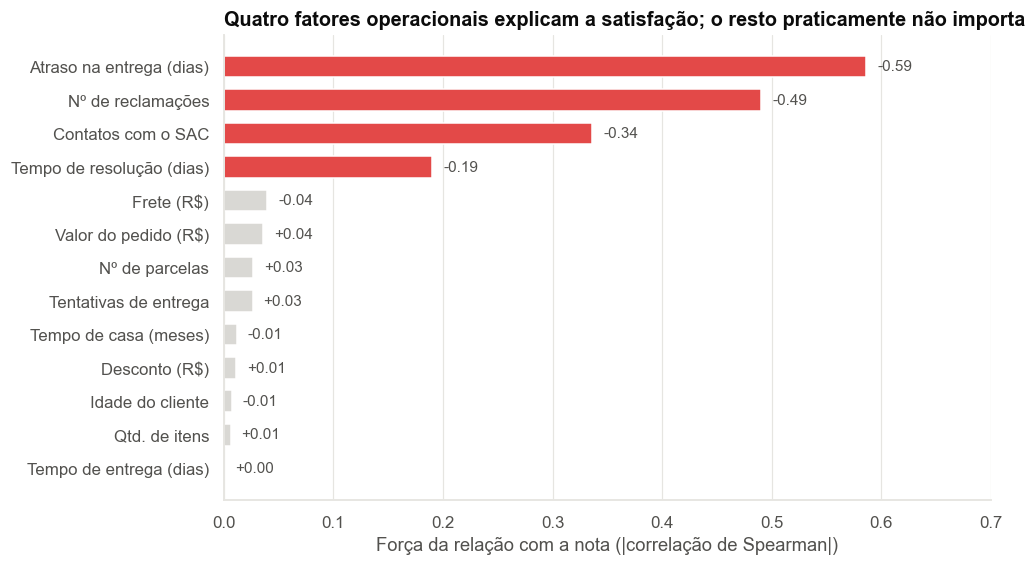

In [5]:
# Gráfico apenas com fatores operacionais (os que a empresa controla ANTES da pesquisa)
operational = correlation_table[correlation_table["grupo"].str.startswith("Operacional")].sort_values("correlacao", key=abs)
colors = [COLOR_ALERT if (abs(r) >= 0.15 and r < 0) else (COLOR_PRIMARY if abs(r) >= 0.15 else COLOR_MUTED) for r in operational["correlacao"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(operational["fator"], operational["correlacao"].abs(), color=colors, height=0.65)
for y, value in enumerate(operational["correlacao"]):
    ax.text(abs(value) + 0.01, y, f"{value:+.2f}", va="center", fontsize=10, color=COLOR_TEXT_SECONDARY)
ax.set_title("Quatro fatores operacionais explicam a satisfação; o resto praticamente não importa")
ax.set_xlabel("Força da relação com a nota (|correlação de Spearman|)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.7)
save_figure(fig, "03_forca_dos_fatores.png")
plt.show()

**Leitura para o negócio:**

- **Atraso na entrega** é, de longe, o fator nº 1;
- Em seguida vêm três fatores de **atendimento**: nº de reclamações, nº de contatos com o SAC e tempo de resolução;
- **Valor do pedido, frete, desconto, parcelas, quantidade de itens, tentativas de entrega, idade e tempo de casa praticamente não se relacionam com a nota.**

Em outras palavras: **o cliente não avalia o "quanto pagou" nem "quem ele é" — avalia se a promessa foi cumprida e se foi bem tratado quando algo deu errado.**

> As variáveis pós-experiência (`csat_internal_score` e `repeat_purchase_30d`) também têm correlação alta, mas ficaram fora do gráfico de propósito: elas são *outras medidas* de satisfação/resultado, coletadas junto ou depois do NPS — não são alavancas operacionais.

## 3. O fator nº 1: atraso na entrega — e o ponto de ruptura

In [6]:
delay_summary = nps_summary_by(df, "delivery_delay_days")
delay_summary

,pedidos,nota_media,pct_detratores,pct_promotores,nps
delivery_delay_days,,,,,
0,277,6.9,51.6,18.1,-33.6
1,615,5.5,74.0,7.2,-66.8
2,646,4.6,87.9,2.0,-85.9
3,525,3.4,96.8,0.6,-96.2
4,270,2.4,99.3,0.0,-99.3
5,116,1.5,100.0,0.0,-100.0
6,34,1.1,100.0,0.0,-100.0
7,14,0.3,100.0,0.0,-100.0
8,3,0.0,100.0,0.0,-100.0


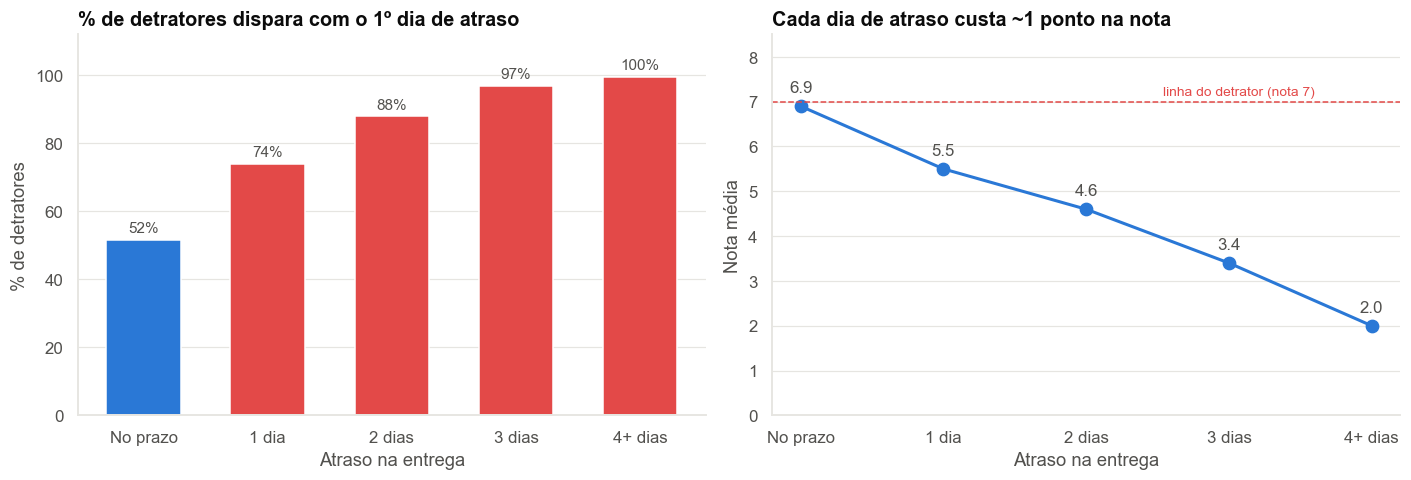

In [7]:
delay_band_summary = nps_summary_by(df, "delay_band")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Painel 1: % de detratores por faixa de atraso
bar_colors = [COLOR_PRIMARY] + [COLOR_ALERT] * (len(delay_band_summary) - 1)
axes[0].bar(delay_band_summary.index.astype(str), delay_band_summary["pct_detratores"], color=bar_colors, width=0.6)
label_bars(axes[0], suffix="%")
axes[0].set_ylim(0, 112)
axes[0].set_title("% de detratores dispara com o 1º dia de atraso")
axes[0].set_ylabel("% de detratores")
axes[0].set_xlabel("Atraso na entrega")

# Painel 2: nota média por faixa de atraso
axes[1].plot(delay_band_summary.index.astype(str), delay_band_summary["nota_media"], color=COLOR_PRIMARY, linewidth=2, marker="o", markersize=8)
for x, y in enumerate(delay_band_summary["nota_media"]):
    axes[1].annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", color=COLOR_TEXT_SECONDARY)
axes[1].axhline(7, color=COLOR_ALERT, linestyle="--", linewidth=1)
axes[1].text(3.6, 7.15, "linha do detrator (nota 7)", color=COLOR_ALERT, fontsize=9, ha="right")
axes[1].set_ylim(0, 8.5)
axes[1].set_title("Cada dia de atraso custa ~1 ponto na nota")
axes[1].set_ylabel("Nota média")
axes[1].set_xlabel("Atraso na entrega")

fig.tight_layout()
save_figure(fig, "04_atraso_ponto_de_ruptura.png")
plt.show()

**Este é o principal "ponto de ruptura" da experiência:**

- Pedido **entregue no prazo**: nota média ~6,9 e ~18% de promotores;
- **1 dia de atraso** já leva 3 em cada 4 clientes para a zona de detrator;
- A partir de **3 dias de atraso**, praticamente **todo** cliente vira detrator (≥ 97%) e nenhum vira promotor.

Ou seja: **o atraso não é um incômodo gradual — o primeiro dia já quebra a confiança, e o terceiro dia torna a recuperação quase impossível**. A janela para agir é antes do atraso ou, no máximo, nas primeiras 24-48h.

### 3.1 Prazo longo × promessa quebrada
Uma pergunta natural: "clientes com entrega mais demorada ficam mais insatisfeitos?". Vamos comparar o **tempo total de entrega** com o **atraso** em relação ao prometido.

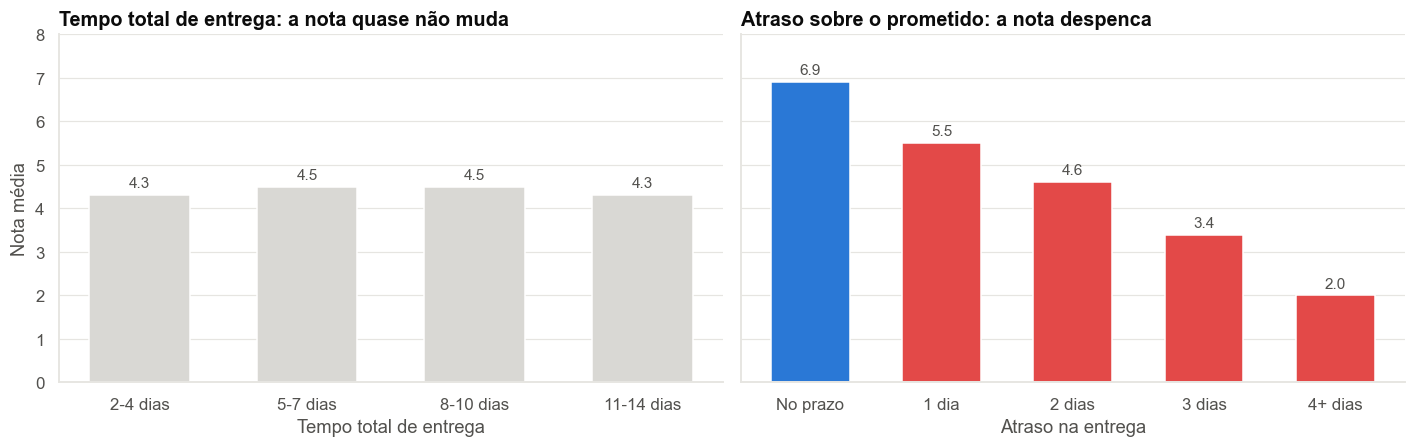

,pedidos,nota_media,pct_detratores,pct_promotores,nps
delivery_time_band,,,,,
2-4 dias,590,4.3,84.7,4.6,-80.2
5-7 dias,548,4.5,85.6,4.2,-81.4
8-10 dias,571,4.5,83.5,4.9,-78.6
11-14 dias,791,4.3,83.8,4.0,-79.8


In [8]:
df["delivery_time_band"] = pd.cut(df["delivery_time_days"], bins=[1, 4, 7, 10, 14],
                                  labels=["2-4 dias", "5-7 dias", "8-10 dias", "11-14 dias"])
time_summary = nps_summary_by(df, "delivery_time_band")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
axes[0].bar(time_summary.index.astype(str), time_summary["nota_media"], color=COLOR_MUTED, width=0.6)
label_bars(axes[0], fmt="{:.1f}")
axes[0].set_title("Tempo total de entrega: a nota quase não muda")
axes[0].set_xlabel("Tempo total de entrega")
axes[0].set_ylabel("Nota média")

axes[1].bar(delay_band_summary.index.astype(str), delay_band_summary["nota_media"],
            color=[COLOR_PRIMARY] + [COLOR_ALERT] * 4, width=0.6)
label_bars(axes[1], fmt="{:.1f}")
axes[1].set_title("Atraso sobre o prometido: a nota despenca")
axes[1].set_xlabel("Atraso na entrega")
axes[0].set_ylim(0, 8)
fig.tight_layout()
save_figure(fig, "05_prazo_vs_atraso.png")
plt.show()
time_summary

**Insight importante:** um cliente que recebe em 12 dias *dentro do prazo prometido* fica tão satisfeito quanto um que recebe em 3 dias. **O que destrói a satisfação não é a demora, é a quebra da expectativa.** Isso abre uma alavanca de baixo custo: **prometer prazos realistas** (com folga) pode reduzir atrasos percebidos sem precisar acelerar a operação.

## 4. Atendimento: reclamações, contatos e tempo de resolução

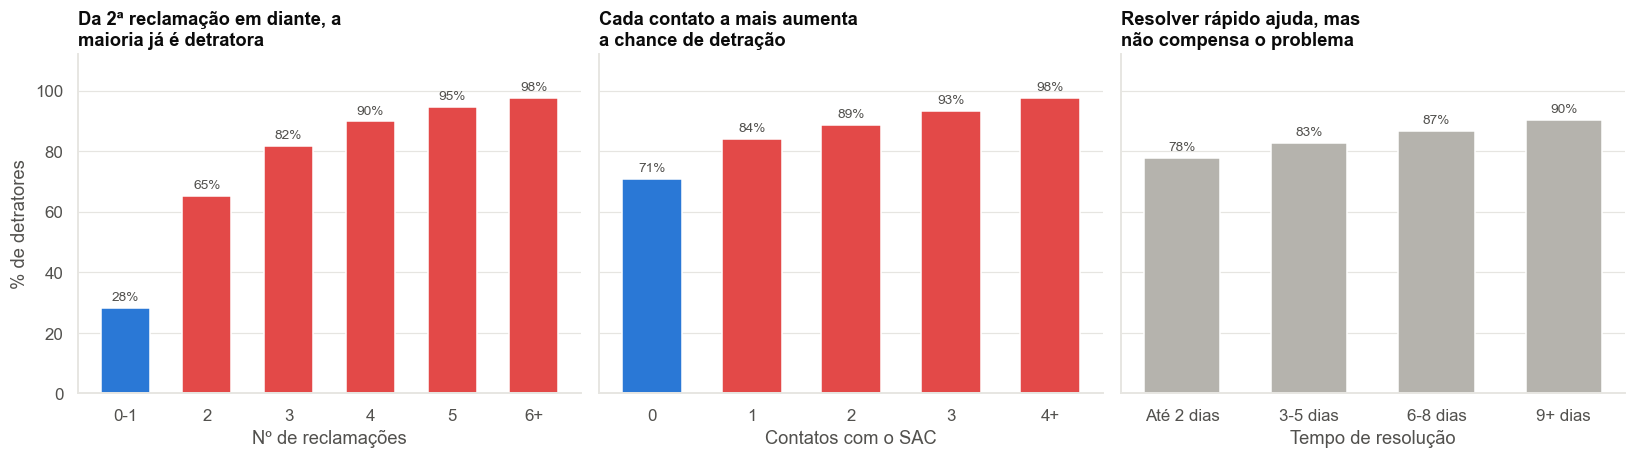

pedidos  nota_media  pct_detratores  \
Reclamações     0-1             145         7.9            28.3   
                2               277         6.1            65.3   
                3               507         4.9            81.7   
                4               600         4.2            89.8   
                5               444         3.6            94.6   
                6+              527         2.8            97.5   
Contatos SAC    0               554         5.5            70.8   
                1               816         4.7            83.9   
                2               640         4.1            88.6   
                3               314         3.2            93.3   
                4+              176         2.5            97.7   
Tempo resolução Até 2 dias      629         5.0            77.7   
                3-5 dias        619         4.5            82.6   
                6-8 dias        637         4.2            86.8   
                9+ dias         615         3.8            90.4   

                            pct_promotores   nps  
Reclamações     0-1                   24.1  -4.1  
                2                     11.2 -54.2  
                3                      4.5 -77.1  
                4                      2.8 -87.0  
                5                      0.7 -93.9  
                6+                     0.2 -97.3  
Contatos SAC    0                     10.3 -60.5  
                1                      4.4 -79.5  
                2                      2.2 -86.4  
                3                      0.6 -92.7  
                4+                     0.6 -97.2  
Tempo resolução Até 2 dias             7.5 -70.3  
                3-5 dias               5.2 -77.4  
                6-8 dias               3.0 -83.8  
                9+ dias                2.0 -88.5

In [9]:
complaints_summary = nps_summary_by(df, "complaints_band")
contacts_summary = nps_summary_by(df, "contacts_band")
resolution_summary = nps_summary_by(df, "resolution_band")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
panels = [
    (complaints_summary, "Nº de reclamações", "Da 2ª reclamação em diante, a\nmaioria já é detratora", 1),
    (contacts_summary, "Contatos com o SAC", "Cada contato a mais aumenta\na chance de detração", 1),
    (resolution_summary, "Tempo de resolução", "Resolver rápido ajuda, mas\nnão compensa o problema", 9),
]
for ax, (summary, xlabel, title, highlight_from) in zip(axes, panels):
    colors = [COLOR_PRIMARY if i < highlight_from else COLOR_ALERT for i in range(len(summary))]
    ax.bar(summary.index.astype(str), summary["pct_detratores"], color=colors, width=0.6)
    label_bars(ax, suffix="%", fontsize=9)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("% de detratores")
axes[0].set_ylim(0, 112)
for bar in axes[2].patches:
    bar.set_facecolor(COLOR_NEUTRAL)
fig.tight_layout()
save_figure(fig, "06_atendimento.png")
plt.show()
pd.concat({"Reclamações": complaints_summary, "Contatos SAC": contacts_summary, "Tempo resolução": resolution_summary})

**Leitura para o negócio:**

- **Reclamações:** com 0-1 reclamação, a nota média fica acima de 7; com **2 reclamações**, 65% já são detratores; com **4 ou mais**, 90%+. É o **segundo ponto de ruptura** da jornada;
- **Contatos com o SAC:** clientes que nunca precisaram falar com o SAC já são majoritariamente detratores (o atraso pesa), mas cada contato adicional piora o quadro — com 3+ contatos, mais de 90% são detratores. **Cada contato é um sinal de que algo não foi resolvido de primeira**;
- **Tempo de resolução:** efeito mais suave — resolver em até 2 dias tem ~78% de detratores contra ~90% acima de 8 dias. Ajuda, mas é a **causa** do contato (o atraso, o problema) que mais pesa.

## 5. Quando os problemas se somam
Na vida real, os problemas não vêm sozinhos. O mapa abaixo cruza os dois fatores mais fortes: **atraso** e **reclamações**. Cada célula mostra a nota média; vermelho = pior, azul = melhor (cinza claro ≈ nota 7, a fronteira do detrator).

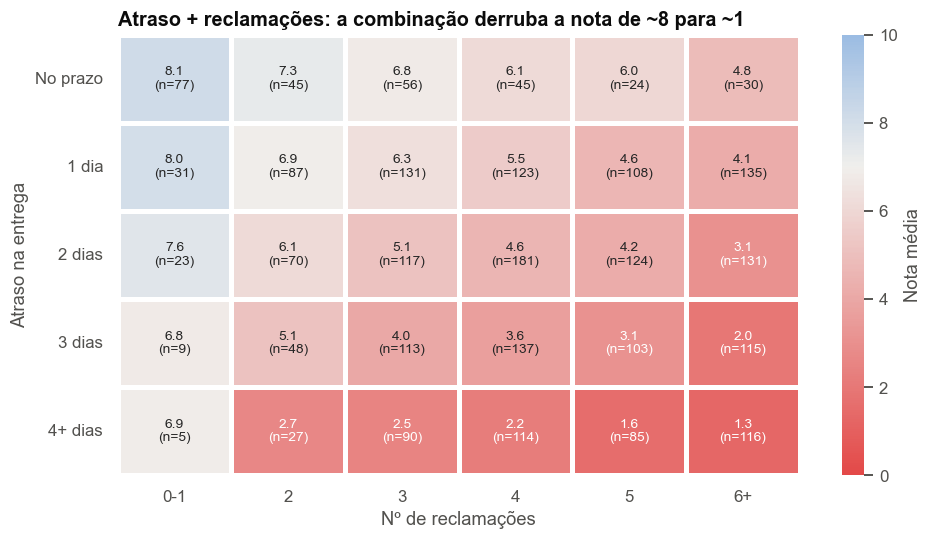

In [10]:
pivot_mean = df.pivot_table(index="delay_band", columns="complaints_band", values="nps_score", aggfunc="mean", observed=False)
pivot_count = df.pivot_table(index="delay_band", columns="complaints_band", values="nps_score", aggfunc="size", observed=False)
annotations = pivot_mean.round(1).astype(str) + "\n(n=" + pivot_count.astype(str) + ")"

fig, ax = plt.subplots(figsize=(10, 5.2))
sns.heatmap(pivot_mean, annot=annotations, fmt="", cmap=DIVERGING_CMAP, center=7, vmin=0, vmax=10,
            linewidths=2, linecolor="white", cbar_kws={"label": "Nota média"}, ax=ax, annot_kws={"fontsize": 9})
ax.set_title("Atraso + reclamações: a combinação derruba a nota de ~8 para ~1")
ax.set_xlabel("Nº de reclamações")
ax.set_ylabel("Atraso na entrega")
ax.tick_params(axis="y", rotation=0)
save_figure(fig, "07_heatmap_atraso_reclamacoes.png")
plt.show()

Os efeitos **se somam**: no canto "no prazo + 0-1 reclamação" a nota média é ~8; no canto oposto ("4+ dias de atraso + 6+ reclamações") cai para ~1. Também fica claro que **é possível compensar parcialmente um atraso** quando ele não vira reclamação: pedidos com 1 dia de atraso e 0-1 reclamação ainda têm nota ~8. Isso sugere que **comunicar o atraso proativamente** (antes de o cliente reclamar) pode preservar a satisfação.

### 5.1 A "jornada sem atritos"

In [11]:
# Definição simples de jornada sem atrito: entregue no prazo, no máximo 1 reclamação e no máximo 1 contato com o SAC
df["journey_type"] = np.where(
    (df["delivery_delay_days"] == 0) & (df["complaints_count"] <= 1) & (df["customer_service_contacts"] <= 1),
    "Sem atritos",
    np.where(df["delivery_delay_days"] >= 3, "Atraso de 3+ dias", "Demais pedidos"),
)
journey_summary = nps_summary_by(df, "journey_type").loc[["Sem atritos", "Demais pedidos", "Atraso de 3+ dias"]]
journey_summary

,pedidos,nota_media,pct_detratores,pct_promotores,nps
journey_type,,,,,
Sem atritos,77,8.1,24.7,33.8,9.1
Demais pedidos,1461,5.2,78.5,5.5,-73.0
Atraso de 3+ dias,962,2.8,98.0,0.3,-97.7


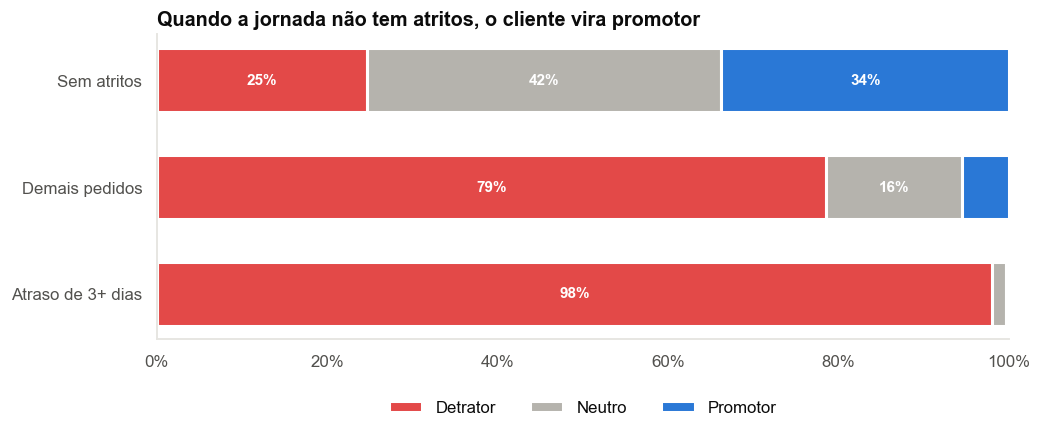

In [12]:
journey_share = (
    df.groupby("journey_type")["nps_category"].value_counts(normalize=True).mul(100)
    .unstack().loc[["Sem atritos", "Demais pedidos", "Atraso de 3+ dias"], ["Detrator", "Neutro", "Promotor"]]
)
fig, ax = plt.subplots(figsize=(10, 3.6))
left = np.zeros(len(journey_share))
for category in journey_share.columns:
    values = journey_share[category].values
    ax.barh(journey_share.index, values, left=left, color=NPS_CATEGORY_COLORS[category], label=category,
            height=0.6, edgecolor="white", linewidth=2)
    for y, (start, width) in enumerate(zip(left, values)):
        if width >= 6:
            ax.text(start + width / 2, y, f"{width:.0f}%", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.set_title("Quando a jornada não tem atritos, o cliente vira promotor")
save_figure(fig, "08_jornada_sem_atritos.png")
plt.show()

Pedidos **sem atritos** (no prazo, ≤ 1 reclamação e ≤ 1 contato) têm um perfil completamente diferente: nota média ~8, NPS positivo e mais promotores que detratores. É um grupo pequeno (77 pedidos, ~3% da base) — o que por si só é um achado: **a jornada ideal é rara hoje**. Já pedidos com **3+ dias de atraso** praticamente não geram promotores. **A empresa sabe "fabricar" promotores — só não consegue fazer isso na maioria dos pedidos.**

## 6. Que tipo de cliente tem NPS mais alto ou mais baixo?

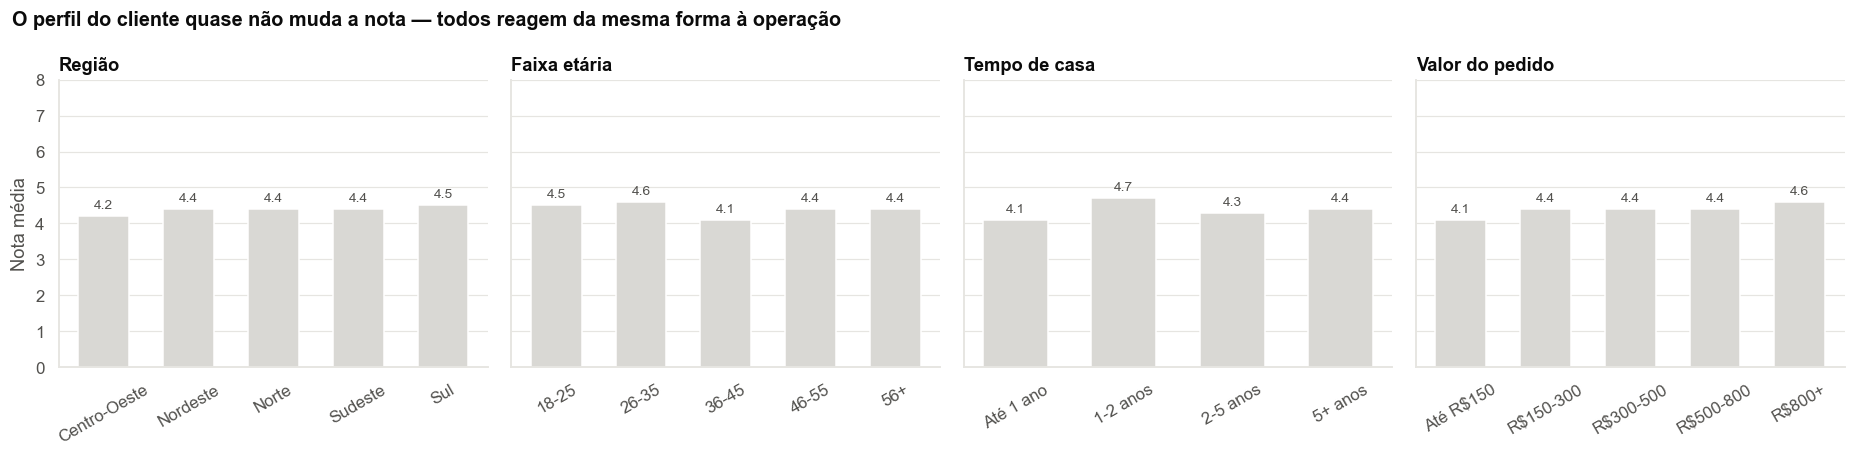

In [13]:
profile_dimensions = {
    "Região": "customer_region",
    "Faixa etária": "age_band",
    "Tempo de casa": "tenure_band",
    "Valor do pedido": "order_value_band",
}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, (title, column) in zip(axes, profile_dimensions.items()):
    summary = nps_summary_by(df, column)
    ax.bar(summary.index.astype(str), summary["nota_media"], color=COLOR_MUTED, width=0.6)
    label_bars(ax, fmt="{:.1f}", fontsize=9)
    ax.set_title(title, fontsize=12)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Nota média")
axes[0].set_ylim(0, 8)
fig.suptitle("O perfil do cliente quase não muda a nota — todos reagem da mesma forma à operação",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_figure(fig, "09_perfil_cliente.png")
plt.show()

In [14]:
# Teste de Kruskal-Wallis: as diferenças de nota entre grupos de perfil são maiores do que o acaso explicaria?
profile_tests = []
for title, column in profile_dimensions.items():
    groups = [g["nps_score"].values for _, g in df.groupby(column, observed=True)]
    statistic, p_value = stats.kruskal(*groups)
    profile_tests.append({"dimensão": title, "p_valor": round(p_value, 3), "diferença relevante?": "sim" if p_value < 0.05 else "não"})
pd.DataFrame(profile_tests)

,dimensão,p_valor,diferença relevante?
0,Região,0.497,não
1,Faixa etária,0.107,não
2,Tempo de casa,0.187,não
3,Valor do pedido,0.230,não


**Leitura:** região, idade, tempo de relacionamento e valor do pedido **não** separam clientes satisfeitos de insatisfeitos — as diferenças são pequenas (décimos de ponto) e estatisticamente indistinguíveis do acaso.

Isso responde à pergunta "que tipo de cliente tem NPS mais alto ou mais baixo?" de forma talvez surpreendente: **não é o tipo de cliente, é o tipo de experiência.** O cliente com NPS alto é aquele que:

- recebeu **no prazo** (ou foi avisado antes de o atraso virar problema);
- **não precisou reclamar** (ou reclamou no máximo uma vez);
- **resolveu tudo com até 1 contato**.

E o cliente com NPS baixo é aquele que passou por **atraso + reclamações + idas e vindas com o SAC**, independentemente de idade, região ou quanto gastou.

> **Implicação prática:** segmentar ações de CX por perfil demográfico teria pouco efeito. As ações devem ser **segmentadas por situação operacional do pedido** — que é exatamente o tipo de informação disponível *antes* da pesquisa de NPS.

## 7. Fatores que **não** fazem diferença (e por que isso também é um insight)

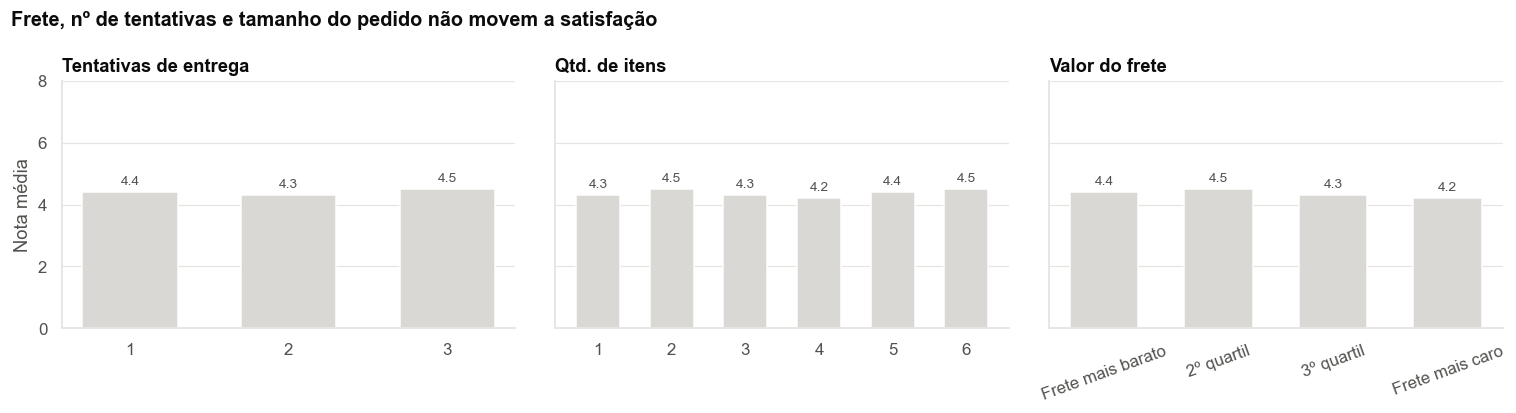

In [15]:
low_impact = {
    "Tentativas de entrega": "delivery_attempts",
    "Qtd. de itens": "items_quantity",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (title, column) in zip(axes[:2], low_impact.items()):
    summary = nps_summary_by(df, column)
    ax.bar(summary.index.astype(str), summary["nota_media"], color=COLOR_MUTED, width=0.6)
    label_bars(ax, fmt="{:.1f}", fontsize=9)
    ax.set_title(title, fontsize=12)
df["freight_band"] = pd.qcut(df["freight_value"], 4, labels=["Frete mais barato", "2º quartil", "3º quartil", "Frete mais caro"])
summary = nps_summary_by(df, "freight_band")
axes[2].bar(summary.index.astype(str), summary["nota_media"], color=COLOR_MUTED, width=0.6)
label_bars(axes[2], fmt="{:.1f}", fontsize=9)
axes[2].set_title("Valor do frete", fontsize=12)
axes[2].tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Nota média")
axes[0].set_ylim(0, 8)
fig.suptitle("Frete, nº de tentativas e tamanho do pedido não movem a satisfação", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_figure(fig, "10_fatores_sem_impacto.png")
plt.show()

- **Frete mais caro não gera mais detratores** → baixar frete ou dar frete grátis como forma de "comprar" satisfação tende a ter retorno baixo;
- **Descontos e parcelamento** também não se relacionam com a nota (seção 2) → não usar cupom como principal ferramenta de recuperação;
- **Tentativas de entrega** não afetam a nota — curiosamente, o cliente parece se importar com a *data* em que recebe, não com quantas vezes o entregador passou.

Saber o que **não** funciona evita gastar orçamento em alavancas erradas.

## 8. Resumo da EDA — respostas às perguntas de negócio

| Pergunta | Resposta |
|---|---|
| **Quais fatores são mais críticos?** | 1º **atraso na entrega**; depois **reclamações**, **contatos com o SAC** e **tempo de resolução**. Fatores de pedido (valor, frete, desconto, parcelas) e de perfil (idade, região, tempo de casa) praticamente não influenciam. |
| **O que mais gera detratores?** | Atraso, sobretudo quando combinado com reclamações. 1 dia de atraso → 74% detratores; 3+ dias → ~100%. 2+ reclamações → maioria detratora. |
| **Existe ponto de ruptura?** | Sim, dois: **o 1º dia de atraso** (a nota cai de ~6,9 para ~5,5 e a maioria vira detratora) e **a 2ª reclamação** (nota cai abaixo de 6,5). A partir de **3 dias de atraso** a recuperação é praticamente impossível. |
| **Que cliente tem NPS mais alto/baixo?** | Não é o perfil demográfico, é a **experiência**: entregue no prazo, sem reclamar e resolvido em até 1 contato → nota alta. Atraso + reclamações + vários contatos → nota baixa, em qualquer região ou faixa etária. |

**Ressalvas:** a análise mostra **associações**, não prova causalidade; a base é um retrato de 2.500 pedidos (um por cliente), sem data, canal, categoria de produto ou transportadora — informações que permitiriam ir mais fundo nas causas do atraso.